In [1]:
from sc_scripts import *
import scanpy as sc
import pandas as pd
import numpy as np
import anndata as ad
from pathlib import Path
import os
import json

path = Path("part_1")

res = 0.1
n_components = 30

# CERVICAL CANCER

In [2]:
type = "cervix"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/cervix/1'),
 PosixPath('part_1/cervix/2'),
 PosixPath('part_1/cervix/3'),
 PosixPath('part_1/cervix/4'),
 PosixPath('part_1/cervix/5')]

Integration concat join='outer': per-sample genes [20615, 20615, 33694, 27984, 27984] -> combined 24901 genes × 35650 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-11-05 13:53:45,405 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-05 13:53:46,680 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-05 13:53:46,735 - harmonypy - INFO - Iteration 1 of 10
2026-11-05 13:53:49,904 - harmonypy - INFO - Iteration 2 of 10
2026-11-05 13:53:53,083 - harmonypy - INFO - Iteration 3 of 10
2026-11-05 13:53:56,31

*********************
35650 cells, 24901 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/sc_scripts.py:396: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/sc_scripts.py:398: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


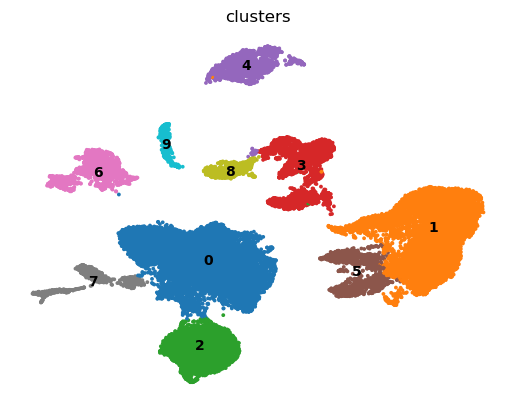

In [4]:
is_10x = True
integrate = True if len(paths) > 1 else False

 
if integrate:
    adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=is_10x)
else:
    adata = run_pipeline(paths[0], n_components=n_components, resolution=res, is_10x=is_10x)

markers = find_top_markers(adata, top_k=30)

print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [ ]:
import json

with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

In [7]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "T cells",
    "2": "Squamous epithelial cells",
    "3": "Macrophages",
    "4": "Plasma cells",
    "5": "NK cells",
    "6": "Fibroblasts",
    "7": "Endothelial cells",
    "8": "B cells",
    "9": "Mast cells",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Malignant cells              12249
1         T cells                      10367
2         Squamous epithelial cells     3779
3         Macrophages                   2347
4         Plasma cells                  1750
5         NK cells                      1585
6         Fibroblasts                   1520
7         Endothelial cells              805
8         B cells                        758
9         Mast cells                     490
Name: count, dtype: int64

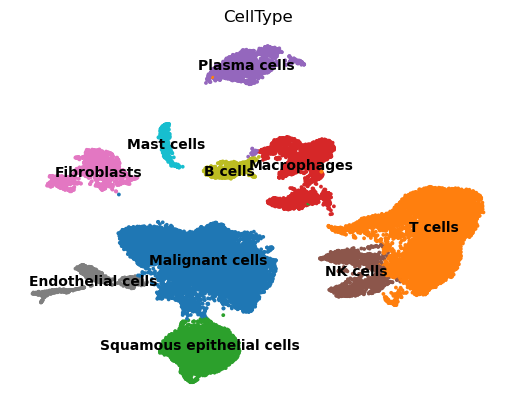

In [8]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

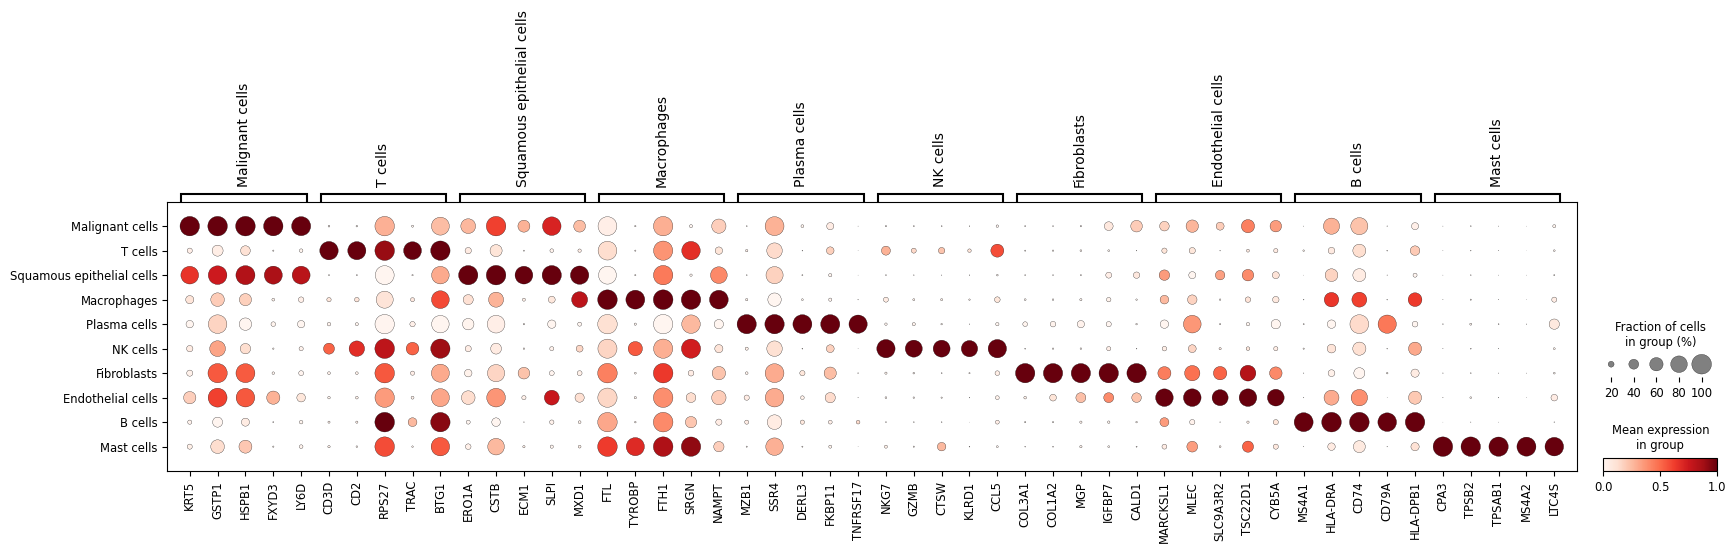

In [9]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [10]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

In [3]:
adata = sc.read_h5ad(data_path / f"{type}_integrated_adata.h5ad")

In [12]:
import subprocess
from pathlib import Path
import pandas as pd
from scipy import io, sparse

out = Path(path / type / "copykat")
out.mkdir(parents=True, exist_ok=True)

max_per_type = 1000
parts = []
for cell_type, idx in adata.obs.groupby("CellType", observed=True).groups.items():
    idx = pd.Index(idx)
    if len(idx) > max_per_type:
        idx = idx.to_series().sample(max_per_type, random_state=0).index
    parts.append(idx)
keep = pd.Index(parts).union(pd.Index([])) if False else parts[0]
for part in parts[1:]:
    keep = keep.append(part)
sub = adata[keep].copy()

counts = sub.layers["counts"]
mat = counts.T.tocsr() if sparse.issparse(counts) else sparse.csr_matrix(counts.T)
io.mmwrite(out / "counts.mtx", mat)
pd.Series(sub.var_names).to_csv(out / "genes.tsv", index=False, header=False)
pd.Series(sub.obs_names).to_csv(out / "barcodes.tsv", index=False, header=False)
ref = sub.obs_names[sub.obs["CellType"].isin(["T cells", "B cells", "Plasma cells"])]
pd.Series(ref).to_csv(out / "normal_cells.tsv", index=False, header=False)
sub.obs[["CellType"]].to_csv(out / "celltype.tsv", sep="\t")


(out / "run_copykat.R").write_text(r"""
library(Matrix)
library(copykat)
setwd("part_1/cervix/copykat")
mat <- as.matrix(readMM("counts.mtx"))
rownames(mat) <- readLines("genes.tsv")
colnames(mat) <- readLines("barcodes.tsv")
normal <- readLines("normal_cells.tsv")
ck <- copykat(
  rawmat = mat,
  id.type = "S",
  cell.line = "no",
  genome = "hg20",
  norm.cell.names = normal,
  KS.cut = 0.1,
  sam.name = "cervix",
  n.cores = 4
)
saveRDS(ck, "cervix_copykat.rds")
pred <- ck$prediction
meta <- read.delim("celltype.tsv", row.names = 1)
pred$CellType <- meta[pred$cell.names, "CellType"]
write.table(pred, "cervix_prediction.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
print(table(pred$CellType, pred$copykat.pred))
""")

subprocess.run(["/usr/local/bin/Rscript", str(out / "run_copykat.R")], check=True)
print(pd.read_csv(out / "cervix_prediction.tsv", sep="\t").groupby(["CellType", "copykat.pred"]).size())


Предупреждение:
В asMethod(object) :
  sparse->dense coercion: allocating vector of size 1.7 GiB


[1] "running copykat v1.1.0"
[1] "step1: read and filter data ..."
[1] "24901 genes, 9053 cells in raw data"
[1] "10806 genes past LOW.DR filtering"
[1] "step 2: annotations gene coordinates ..."
[1] "start annotation ..."
[1] "step 3: smoothing data with dlm ..."
[1] "step 4: measuring baselines ..."
[1] "2620 known normal cells found in dataset"
[1] "run with known normal..."
[1] "baseline is from known input"
[1] "step 5: segmentation..."
[1] "step 6: convert to genomic bins..."
[1] "step 7: adjust baseline ..."
[1] "step 8: final prediction ..."
[1] "step 9: saving results..."
[1] "step 10: ploting heatmap ..."
Time difference of 1.444202 hours
                           
                            aneuploid diploid not.defined
  B cells                           1     710          47
  Endothelial cells               226     550          29
  Fibroblasts                      11     981           8
  Macrophages                      22     759         219
  Malignant cells        

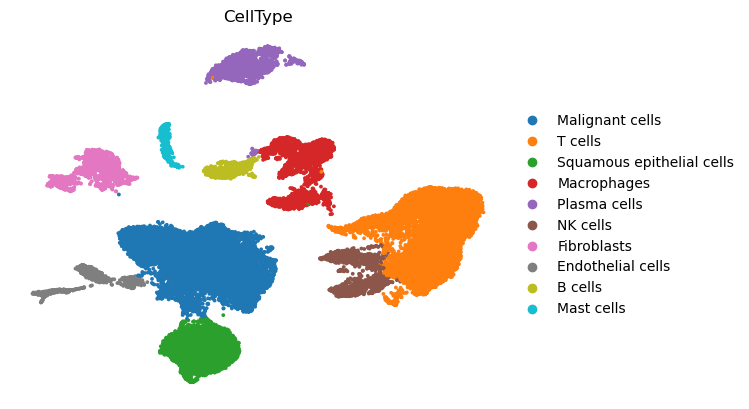

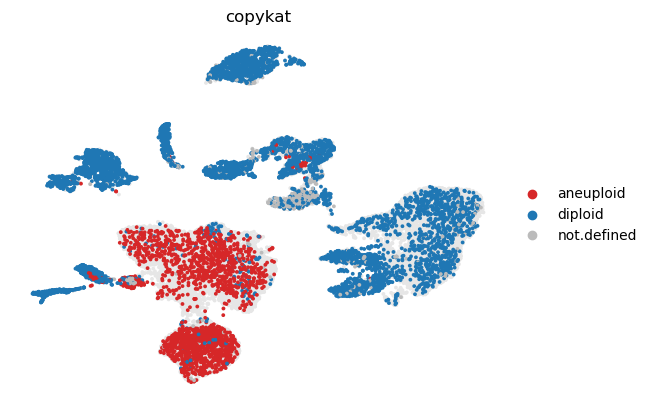

copykat,aneuploid,diploid,not.defined
CellType,,,
Malignant cells,0.894,0.098,0.008
T cells,0.000,0.949,0.051
Squamous epithelial cells,0.947,0.041,0.012
Macrophages,0.022,0.759,0.219
Plasma cells,0.008,0.937,0.055
NK cells,0.001,0.957,0.042
Fibroblasts,0.011,0.981,0.008
Endothelial cells,0.281,0.683,0.036
B cells,0.001,0.937,0.062


In [13]:
pred = pd.read_csv("part_1/cervix/copykat/cervix_prediction.tsv", sep="\t")
adata.obs["copykat"] = pd.Categorical(
    pred.set_index("cell.names")["copykat.pred"].reindex(adata.obs_names),
    categories=["aneuploid", "diploid", "not.defined"],
)
sc.pl.umap(adata, color="CellType", size=30, alpha=1, frameon=False)

sc.pl.umap(
    adata,
    color="copykat",
    palette={"aneuploid": "#d62728", "diploid": "#1f77b4", "not.defined": "#bbbbbb"},
    na_color="#e6e6e6",
    na_in_legend=False,
    size=30,
    alpha=1,
    frameon=False,
)

pd.crosstab(adata.obs["CellType"], adata.obs["copykat"], normalize="index").round(3)

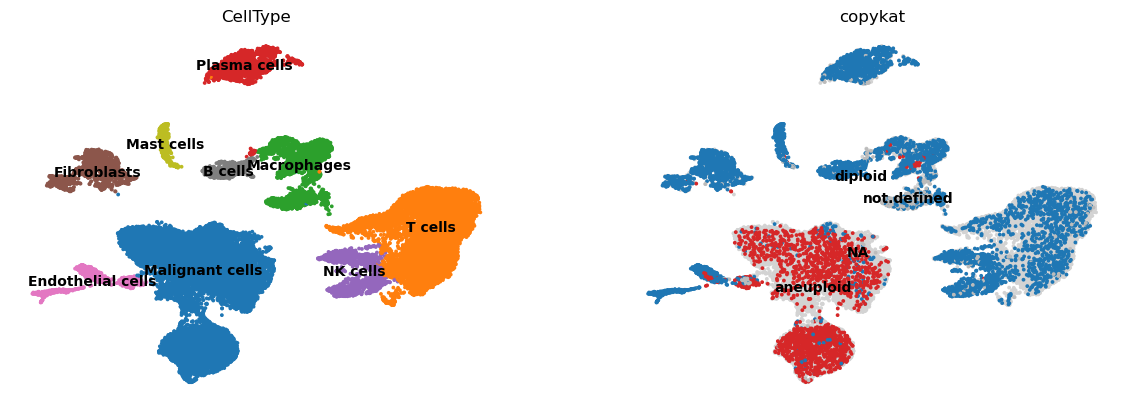

In [19]:
adata.obs["CellType"] = adata.obs["CellType"].replace("Squamous epithelial cells", "Malignant cells")

sc.pl.umap(adata, color=['CellType', 'copykat'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [21]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# BREAST CANCER

In [3]:
type = "breast"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/breast/1'),
 PosixPath('part_1/breast/2'),
 PosixPath('part_1/breast/3'),
 PosixPath('part_1/breast/4'),
 PosixPath('part_1/breast/5')]

Integration concat join='outer': per-sample genes [33538, 33538, 33538, 33538, 33538] -> combined 23570 genes × 20675 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 17:18:17,168 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 17:18:17,915 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 17:18:17,942 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 17:18:19,404 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 17:18:20,801 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 17:18:22,22

*********************
20675 cells, 23570 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:309: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:311: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


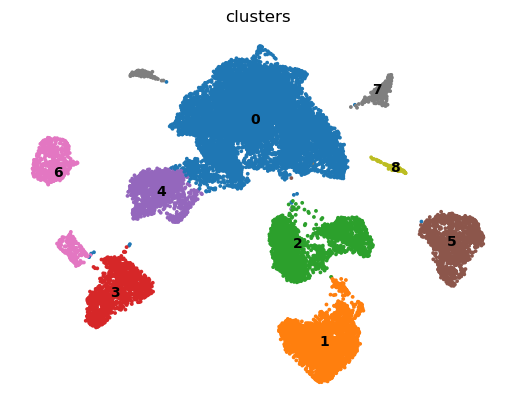

In [ ]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [20]:
# Filtering out the low quality cells
adata = adata[~adata.obs["clusters"].isin(["7"])].copy()
# sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [21]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Macrophages",
    "2": "Plasma cells",
    "3": "Fibroblasts",
    "4": "Cycling cells",
    "5": "T cells",
    "6": "Endothelial cells",
    "8": "Mast cells",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         Malignant cells      10584
1         Macrophages           2679
2         Plasma cells          2381
3         Fibroblasts           1305
4         Cycling cells         1291
5         T cells               1224
6         Endothelial cells      744
8         Mast cells              94
Name: count, dtype: int64

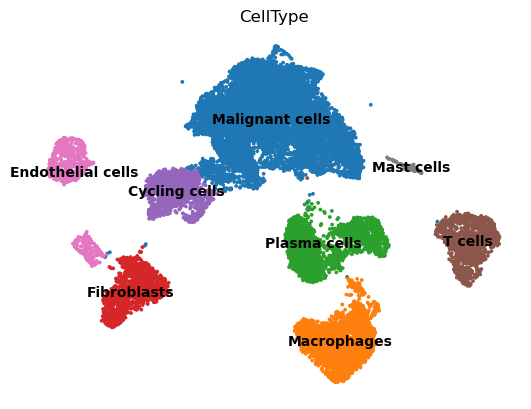

In [22]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

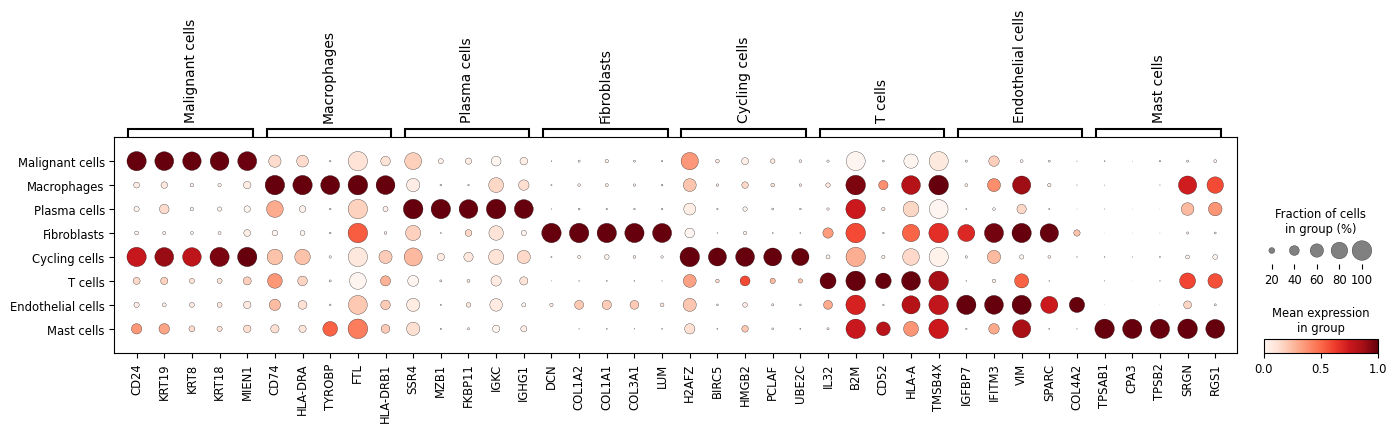

In [ ]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Colorectal cancer

In [4]:
type = "colorectal"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/colorectal/1'),
 PosixPath('part_1/colorectal/2'),
 PosixPath('part_1/colorectal/3'),
 PosixPath('part_1/colorectal/4'),
 PosixPath('part_1/colorectal/5')]

Integration concat join='outer': per-sample genes [33694, 33694, 33694, 33694, 33694] -> combined 23201 genes × 20172 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 17:56:49,347 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 17:56:50,088 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 17:56:50,114 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 17:56:51,496 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 17:56:52,909 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 17:56:54,29

*********************
20172 cells, 23201 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:309: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:311: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


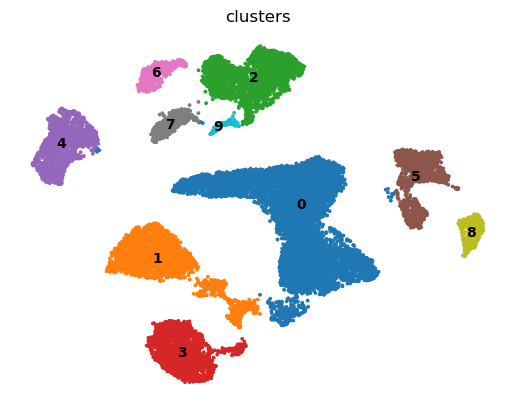

In [31]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [32]:
cluster_annotation = {
    "0": "T cells",
    "1": "B cells",
    "2": "Macrophages",
    "3": "Plasma cells",
    "4": "Malignant cells",
    "5": "Fibroblasts",
    "6": "Mast cells",
    "7": "Neutrophils",
    "8": "Endothelial cells",
    "9": "Dendritic cells"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         T cells              8770
1         B cells              2865
2         Macrophages          2451
3         Plasma cells         1946
4         Malignant cells      1476
5         Fibroblasts          1220
6         Mast cells            501
7         Neutrophils           435
8         Endothelial cells     359
9         Dendritic cells       149
Name: count, dtype: int64

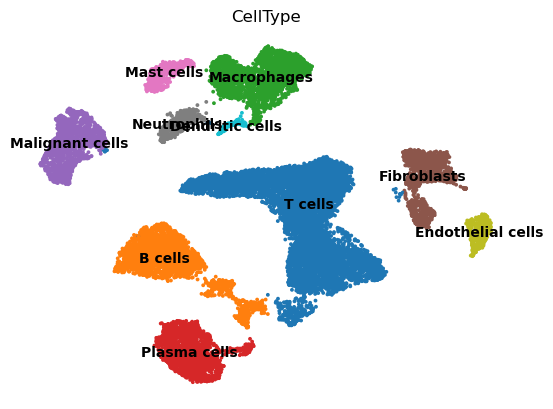

In [33]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

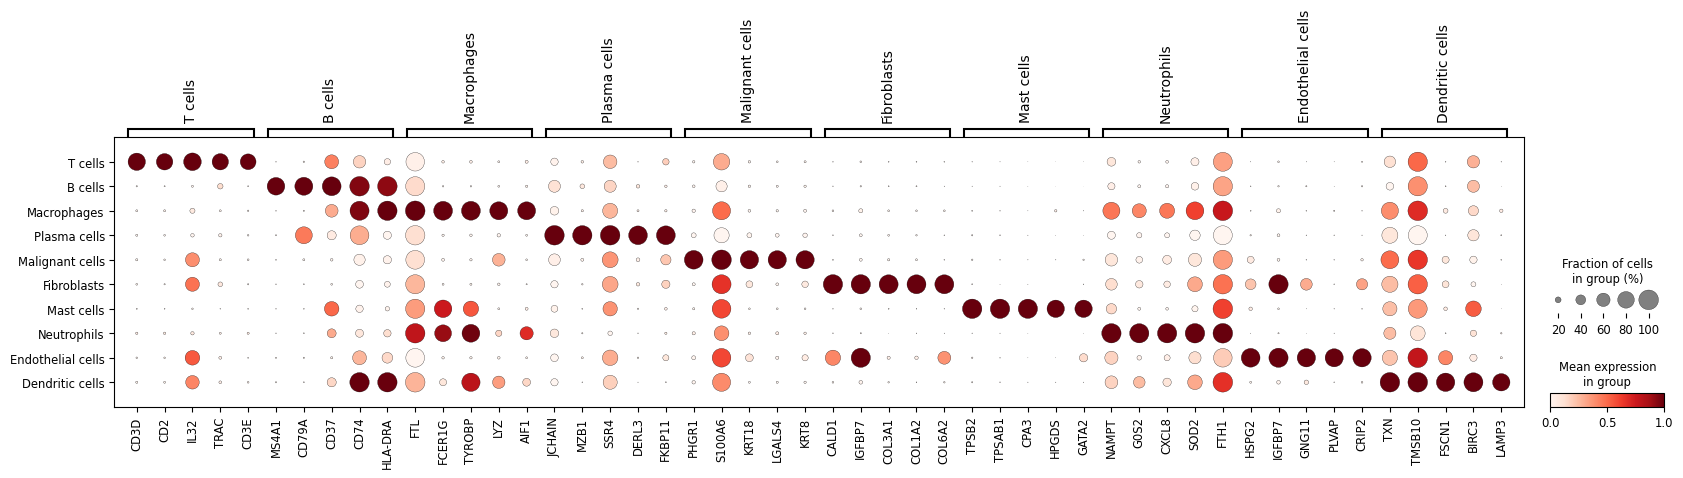

In [34]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Gastric cancer

In [5]:
type = "GC"
data_path = path / type

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in range(1, 5)]
paths

[PosixPath('part_1/GC/1/GSM5573467_sample2.csv.gz'),
 PosixPath('part_1/GC/2/GSM5573473_sample8.csv.gz'),
 PosixPath('part_1/GC/3/GSM5573480_sample15.csv.gz'),
 PosixPath('part_1/GC/4/GSM5573482_sample17.csv.gz')]

Integration concat join='outer': per-sample genes [26571, 26571, 26571, 26571] -> combined 23262 genes × 30117 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 18:15:45,212 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 18:15:46,286 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 18:15:46,330 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 18:15:48,974 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 18:15:51,618 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 18:15:54,291 - harmonypy - INFO - Iteration 4 of 10
2026-10-26 18:15:57,201 - harmonypy - INFO - Iteration 5 of 10
2026-10-26 18:15:59,917 - harmonypy - INFO - Iteration 6 of 10
2026-10-26 18:16:02,549 - harmonypy

*********************
30117 cells, 23262 genes
*********************


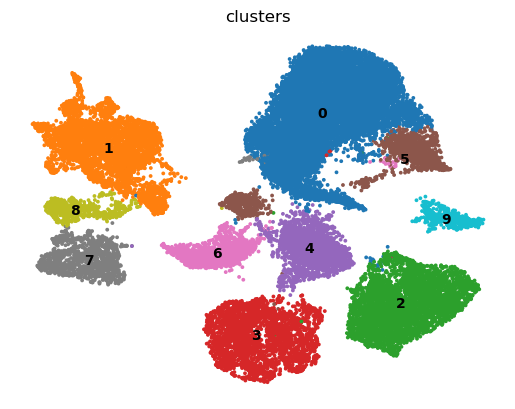

In [41]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [42]:
cluster_annotation = {
    "0": "T cells",
    "1": "Fibroblasts",
    "2": "Macrophages",
    "3": "Malignant cells",
    "4": "Plasma cells",
    "5": "NK cells",
    "6": "B cells",
    "7": "Endothelial cells",
    "8": "Pericytes",
    "9": "Mast cells"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         T cells              11813
1         Fibroblasts           4001
2         Macrophages           3999
3         Malignant cells       3126
4         Plasma cells          2065
5         NK cells              1421
6         B cells               1347
7         Endothelial cells     1214
8         Pericytes              608
9         Mast cells             523
Name: count, dtype: int64

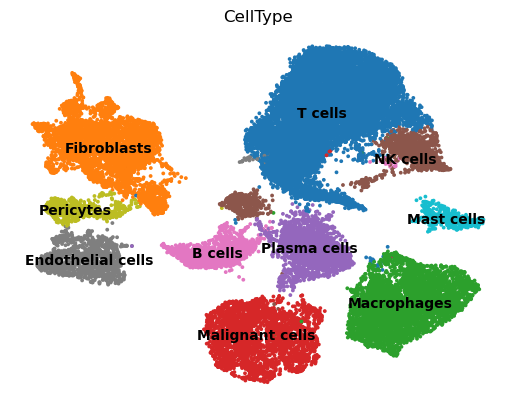

In [45]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scan

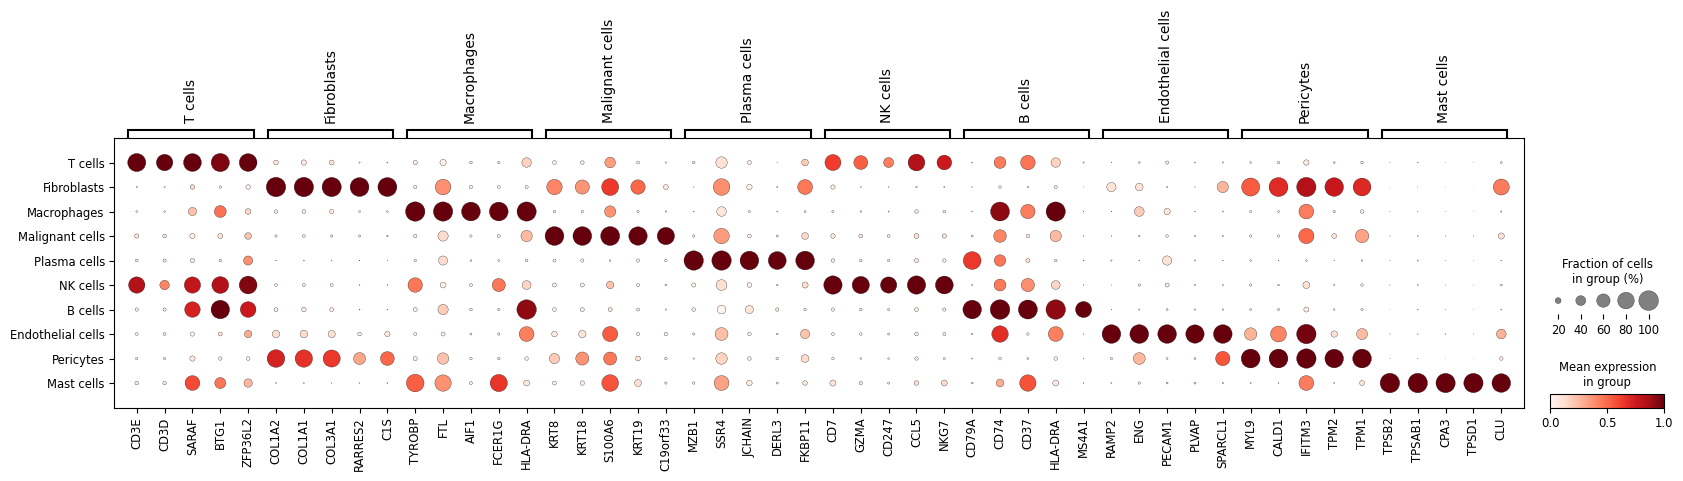

In [44]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Hepatocellular carcinoma

In [6]:
type = "HCC"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/HCC/1'),
 PosixPath('part_1/HCC/2'),
 PosixPath('part_1/HCC/3'),
 PosixPath('part_1/HCC/4'),
 PosixPath('part_1/HCC/5')]

Integration concat join='outer': per-sample genes [27401, 58336, 58336, 58336, 58336] -> combined 28413 genes × 20234 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 19:21:34,161 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 19:21:35,042 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 19:21:35,067 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 19:21:36,800 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 19:21:38,363 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 19:21:39,97

*********************
20234 cells, 28413 genes
*********************


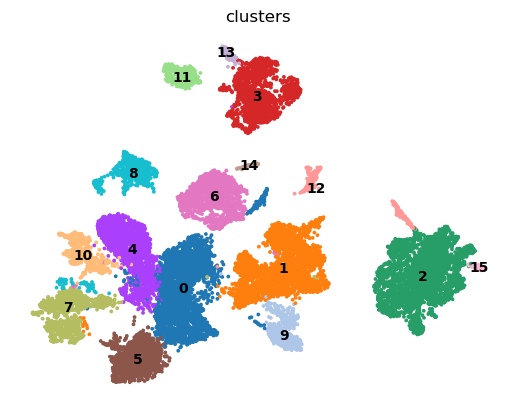

In [ ]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.3, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [57]:
adata = adata[~adata.obs['clusters'].isin(['14', '15'])].copy()

In [58]:
cluster_annotation = {
    "0": "Dendritic cells 2",
    "1": "T cells",
    "2": "Malignant cells",
    "3": "Endothelial cells",
    "4": "Monocytes",
    "5": "Kupffer cells",
    "6": "Plasma cells",
    "7": "Cycling cells",
    "8": "Dendritic cells 1",
    "9": "B cells",
    "10": "Neutrophils",
    "11": "VSMCs",
    "12": "Mast cells",
    "13": "Endothelial cells"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         Dendritic cells 2    3384
1         T cells              3160
2         Malignant cells      3160
3         Endothelial cells    1855
4         Monocytes            1788
5         Kupffer cells        1663
6         Plasma cells         1481
7         Cycling cells        1040
8         Dendritic cells 1     784
9         B cells               563
10        Neutrophils           522
11        VSMCs                 354
12        Mast cells            272
13        Endothelial cells     123
Name: count, dtype: int64

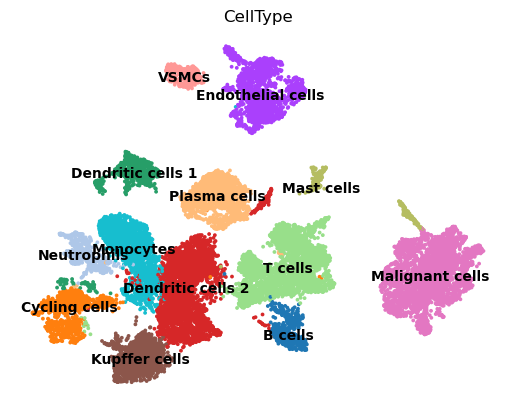

In [59]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

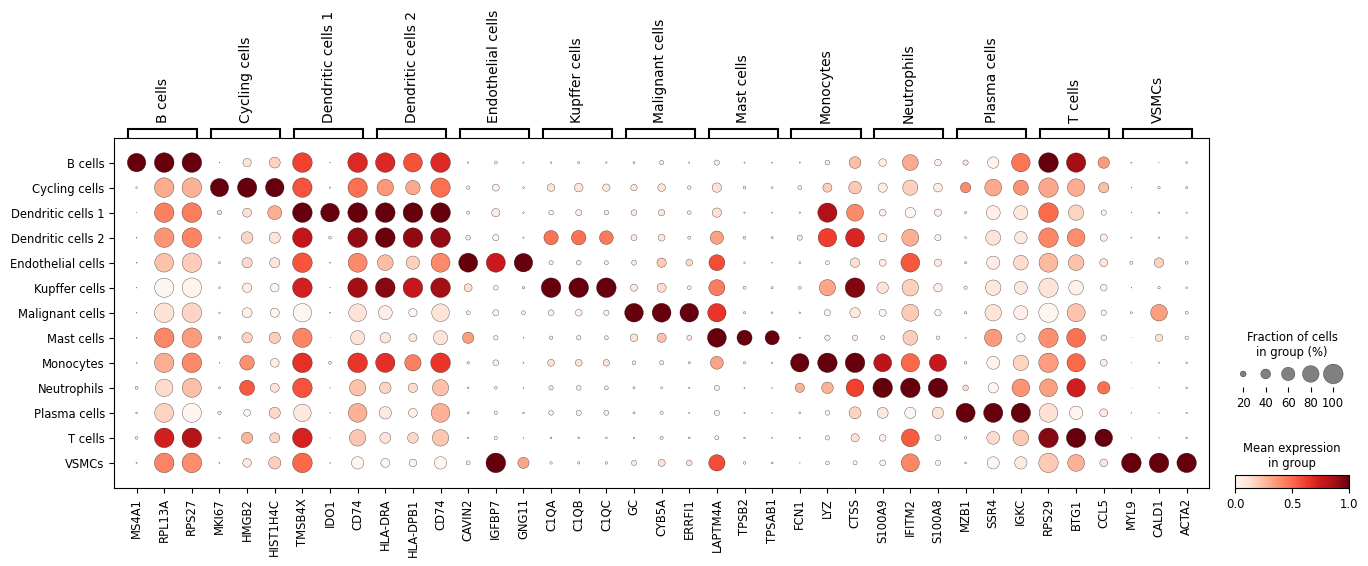

In [60]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=3)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Lung adenocarcinoma

In [7]:
type = "LUAD"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/LUAD/1'),
 PosixPath('part_1/LUAD/2'),
 PosixPath('part_1/LUAD/3'),
 PosixPath('part_1/LUAD/4'),
 PosixPath('part_1/LUAD/5')]

Integration concat join='outer': per-sample genes [33538, 33538, 33538, 33538, 33538] -> combined 25263 genes × 30136 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 20:12:02,165 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 20:12:03,070 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 20:12:03,115 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 20:12:05,804 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 20:12:08,473 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 20:12:11,00

*********************
30136 cells, 25263 genes
*********************


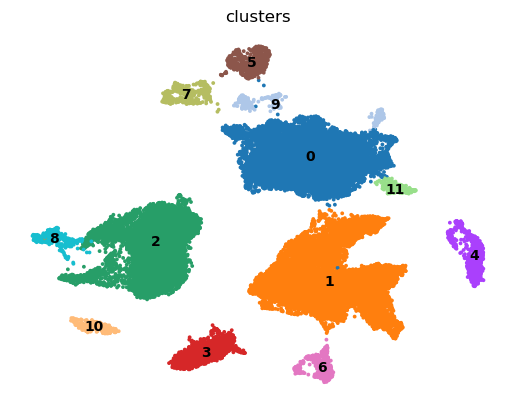

In [63]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [65]:
adata = adata[~adata.obs['clusters'].isin(['9'])].copy()

In [66]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Macrophages",
    "2": "T cells",
    "3": "B cells",
    "4": "Ciliated cells",
    "5": "Endothelial cells",
    "6": "Mast cells",
    "7": "Fibroblasts",
    "8": "Cycling cells",
    "10": "Plasma cells",
    "11": "Secretory airway epithelial cells" 
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                         
0         Malignant cells                      9261
1         Macrophages                          9169
2         T cells                              7036
3         B cells                              1322
4         Ciliated cells                        722
5         Endothelial cells                     535
6         Mast cells                            460
7         Fibroblasts                           425
8         Cycling cells                         357
10        Plasma cells                          291
11        Secretory airway epithelial cells     231
Name: count, dtype: int64

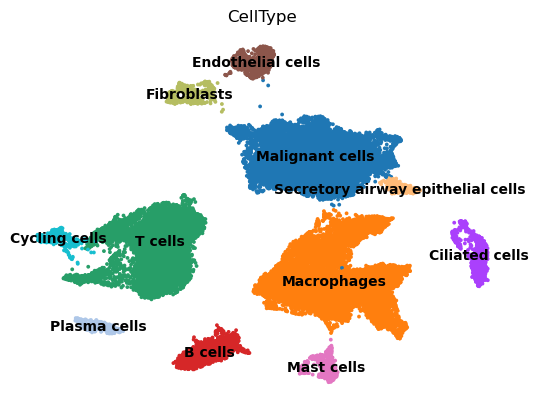

In [67]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

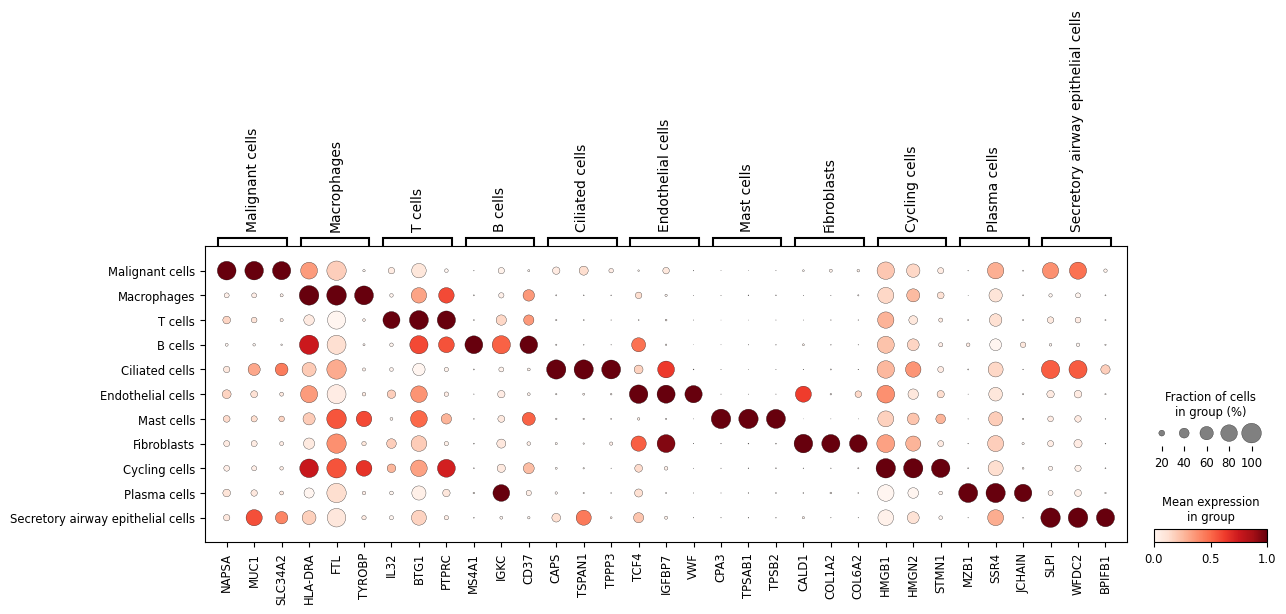

In [68]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=3)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Ovarian cancer

In [10]:
type = "ovarian"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 7)]
paths

[PosixPath('part_1/ovarian/1'),
 PosixPath('part_1/ovarian/2'),
 PosixPath('part_1/ovarian/3'),
 PosixPath('part_1/ovarian/4'),
 PosixPath('part_1/ovarian/5'),
 PosixPath('part_1/ovarian/6')]

Integration concat join='outer': per-sample genes [27984, 27984, 27984, 27984, 27984, 27984] -> combined 21677 genes × 19688 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-26 21:43:38,399 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-26 21:43:39,052 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-26 21:43:39,083 - harmonypy - INFO - Iteration 1 of 10
2026-10-26 21:43:40,740 - harmonypy - INFO - Iteration 2 of 10
2026-10-26 21:43:42,504 - harmonypy - INFO - Iteration 3 of 10
2026-10-26 21:43:44,32

*********************
19688 cells, 21677 genes
*********************


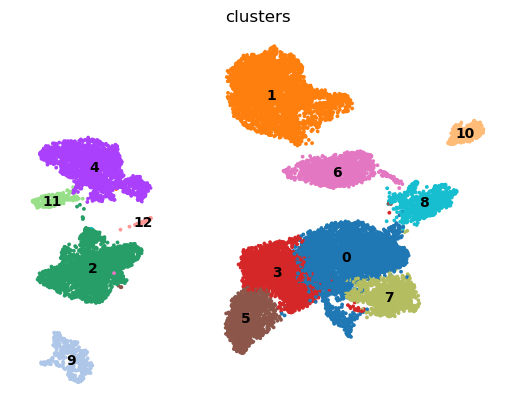

In [73]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=0.3, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [83]:
cluster_annotation = {
    "0": "T cells",
    "1": "Malignant cells",
    "2": "Monocytes and macrophages",
    "3": "T cells",
    "4": "Fibroblasts",
    "5": "T cells",
    "6": "Plasma cells",
    "7": "NK cells",
    "8": "Cycling cells",
    "9": "Endothelial cells",
    "10": "B cells",
    "11": "Pericytes",
    "12": "Plasmacytoid DCs"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         T cells                      4372
1         Malignant cells              3831
2         Monocytes and macrophages    2258
3         T cells                      2096
4         Fibroblasts                  1919
5         T cells                      1315
6         Plasma cells                 1163
7         NK cells                     1090
8         Cycling cells                 701
9         Endothelial cells             392
10        B cells                       284
11        Pericytes                     207
12        Plasmacytoid DCs               60
Name: count, dtype: int64

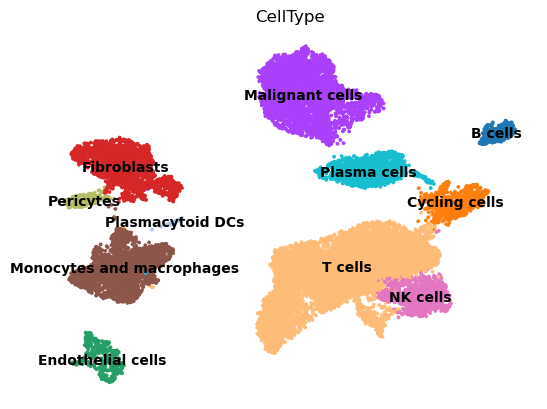

In [84]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

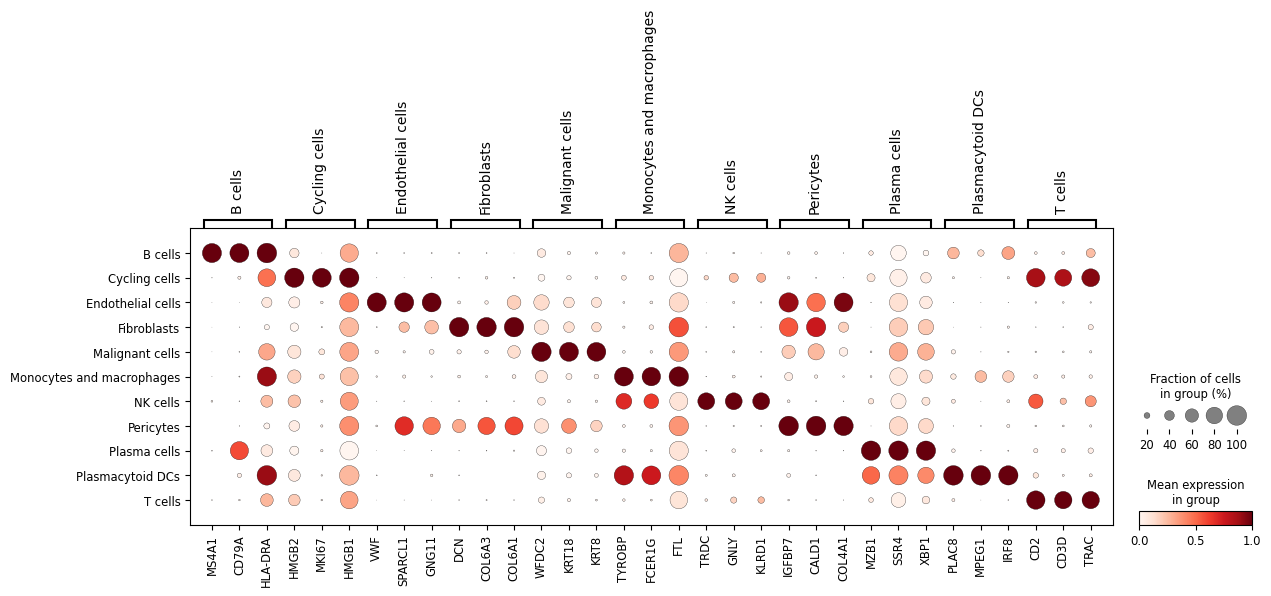

In [85]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=3)

In [ ]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Melanoma

In [3]:
type = "melanoma"
data_path = path / type

paths = [data_path / f'GSM851568{i}' for i in range(4)]
paths

[PosixPath('part_1/melanoma/GSM8515680'),
 PosixPath('part_1/melanoma/GSM8515681'),
 PosixPath('part_1/melanoma/GSM8515682'),
 PosixPath('part_1/melanoma/GSM8515683')]

Integration concat join='outer': per-sample genes [36601, 36601, 36601, 36601] -> combined 29035 genes × 63523 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-11-04 18:12:30,940 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-04 18:12:33,469 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-04 18:12:33,586 - harmonypy - INFO - Iteration 1 of 10
2026-11-04 18:12:41,574 - harmonypy - INFO - Iteration 2 of 10
2026-11-04 18:12:48,730 - harmonypy - INFO - Iteration 3 of 10
2026-11-04 18:12:56,57

*********************
63523 cells, 29035 genes
*********************


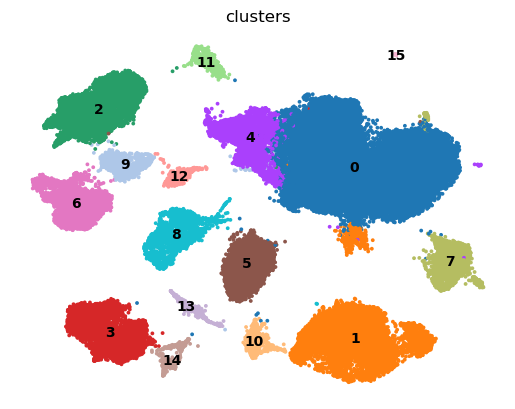

In [4]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.2, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [14]:
adata = adata[~adata.obs['clusters'].isin(['15', '17'])].copy()

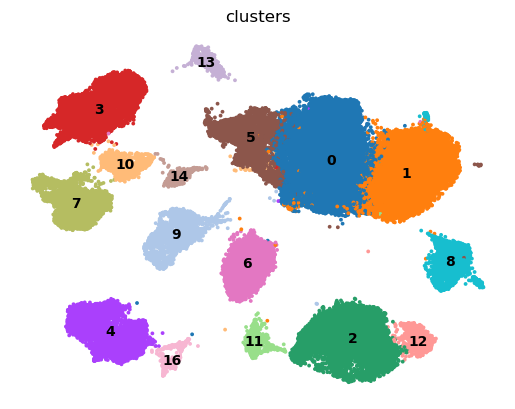

In [15]:
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [16]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Malignant cells",
    "2": "T cells",
    "3": "Macrophages",
    "4": "Myeloid mononuclear cells",
    "5": "Malignant cells",
    "6": "Cycling cells",
    "7": "Endothelial cells",
    "8": "Sweat gland epithelial cells",
    "9": "Keratinocytes",
    "10": "VSMCs",
    "11" : "B cells",
    "13": "Lymphatic endothelial cells",
    "12": "T cells",
    "14": "Mast cells",
    "16" : 'Myeloid mononuclear cells'
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                    
0         Malignant cells                 17087
1         Malignant cells                 12509
2         T cells                          7290
3         Macrophages                      4963
4         Myeloid mononuclear cells        3578
5         Malignant cells                  3461
6         Cycling cells                    3102
7         Endothelial cells                2613
8         Sweat gland epithelial cells     2417
9         Keratinocytes                    1617
10        VSMCs                            1064
11        B cells                           710
12        T cells                           708
13        Lymphatic endothelial cells       525
14        Mast cells                        435
16        Myeloid mononuclear cells         387
Name: count, dtype: int64

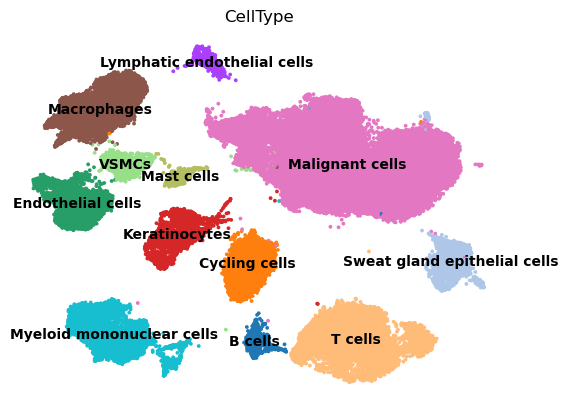

In [17]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [18]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Pancreas cancer

In [12]:
type = "pancreas"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/pancreas/1'),
 PosixPath('part_1/pancreas/2'),
 PosixPath('part_1/pancreas/3'),
 PosixPath('part_1/pancreas/4'),
 PosixPath('part_1/pancreas/5')]

Integration concat join='outer': per-sample genes [33694, 33694, 33694, 33694, 33694] -> combined 21525 genes × 9089 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-27 13:49:13,300 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-27 13:49:13,950 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-27 13:49:13,970 - harmonypy - INFO - Iteration 1 of 10
2026-10-27 13:49:14,611 - harmonypy - INFO - Iteration 2 of 10
2026-10-27 13:49:15,284 - harmonypy - INFO - Iteration 3 of 10
2026-10-27 13:49:15,97

*********************
9089 cells, 21525 genes
*********************


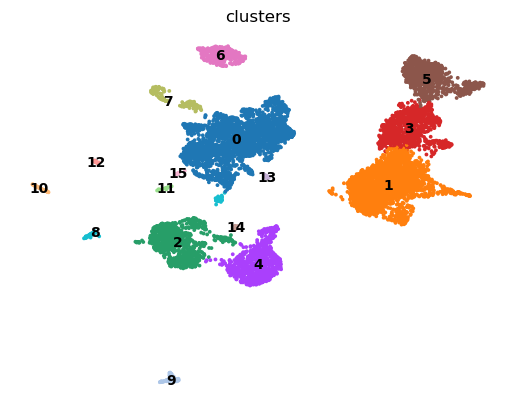

In [6]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.2, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [12]:
adata = adata[~adata.obs['clusters'].isin(['11', '13', '14', '15', '8'])].copy()

In [13]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "T cells",
    "2": "Macrophages",
    "3": "T cells",
    "4": "Monocytes",
    "5": "NK cells",
    "6": "B cells",
    "7": "Acinar cells", 
    "9": "Fibroblasts",
    "10": "Mast cells", 
    "12": "Endothelial cells", 
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         Malignant cells      2547
1         T cells              2431
2         Macrophages           918
3         T cells               886
4         Monocytes             821
5         NK cells              776
6         B cells               280
7         Acinar cells          158
9         Fibroblasts            59
10        Mast cells             46
12        Endothelial cells      20
Name: count, dtype: int64

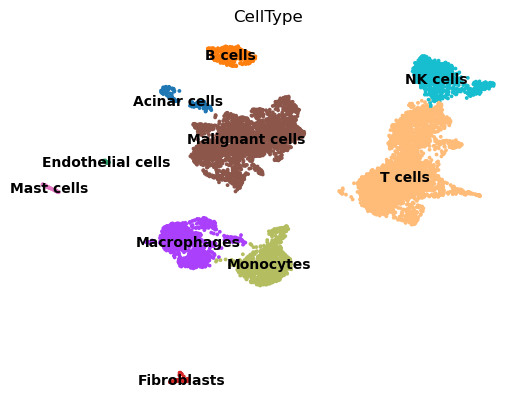

In [14]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [15]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Renal cell cancer

In [11]:
type = "RCC"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_1/RCC/1'),
 PosixPath('part_1/RCC/2'),
 PosixPath('part_1/RCC/3'),
 PosixPath('part_1/RCC/4'),
 PosixPath('part_1/RCC/5')]

Integration concat join='outer': per-sample genes [33538, 33538, 33538, 33538, 33538] -> combined 25101 genes × 43818 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-27 15:02:54,990 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-27 15:02:56,293 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-27 15:02:56,358 - harmonypy - INFO - Iteration 1 of 10
2026-10-27 15:03:00,692 - harmonypy - INFO - Iteration 2 of 10
2026-10-27 15:03:04,920 - harmonypy - INFO - Iteration 3 of 10
2026-10-27 15:03:09,29

*********************
43818 cells, 25101 genes
*********************


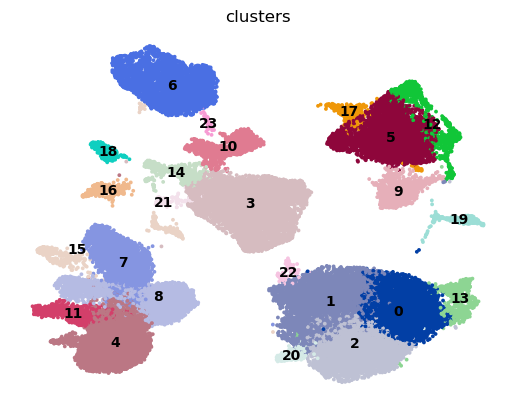

In [22]:
adata = run_pipeline_integrate(paths, n_components=30, resolution=0.7, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [ ]:
adata = adata[~adata.obs['clusters'].isin(['8', '15', '21', '23'])].copy()

In [ ]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Malignant cells",
    "2": "Malignant cells",
    "3": "Macrophages",
    "4": "T cells",
    "5": "Endothelial cells",
    "6": "Pericytes",
    "7": "T cells", 
    "9": "Endothelial cells", 
    "10": "Monocytes", 
    "11": "NK cells",
    "12": "Endothelial cells",
    "13": "Malignant cells",
    "14": "DCs",

    "16": "B cells",
    "17": "Endothelial cells",
    "18": "Plasma cells",
    "19": "Mast cells",
    "20": "Collecting duct cells",
    "22": "Malignant cells"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType             
0         Malignant cells          5683
1         Malignant cells          5220
2         Malignant cells          4973
3         Macrophages              4829
4         T cells                  3963
5         Endothelial cells        3670
6         Pericytes                3247
7         T cells                  2926
9         Endothelial cells         945
10        Monocytes                 916
11        NK cells                  737
12        Endothelial cells         702
13        Malignant cells           518
14        DCs                       494
16        B cells                   372
17        Endothelial cells         337
18        Plasma cells              269
19        Mast cells                247
20        Collecting duct cells     222
22        Malignant cells            74
Name: count, dtype: int64

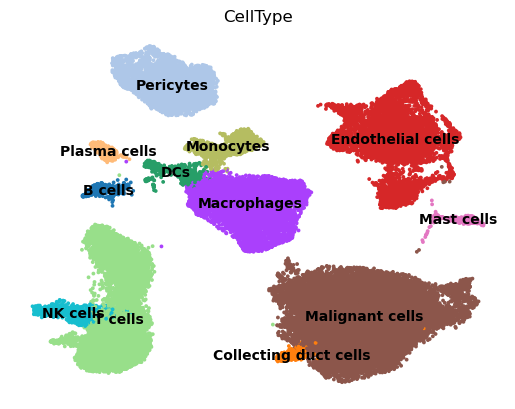

In [45]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

### CopyKAT through R

In [ ]:
import subprocess
from pathlib import Path
import pandas as pd
from scipy import io, sparse

out = Path("part_1/RCC/copykat")
out.mkdir(parents=True, exist_ok=True)

max_per_type = 1000
parts = []
for cell_type, idx in adata.obs.groupby("CellType", observed=True).groups.items():
    idx = pd.Index(idx)
    if len(idx) > max_per_type:
        idx = idx.to_series().sample(max_per_type, random_state=0).index
    parts.append(idx)
keep = pd.Index(parts).union(pd.Index([])) if False else parts[0]
for part in parts[1:]:
    keep = keep.append(part)
sub = adata[keep].copy()

counts = sub.layers["counts"]
mat = counts.T.tocsr() if sparse.issparse(counts) else sparse.csr_matrix(counts.T)
io.mmwrite(out / "counts.mtx", mat)
pd.Series(sub.var_names).to_csv(out / "genes.tsv", index=False, header=False)
pd.Series(sub.obs_names).to_csv(out / "barcodes.tsv", index=False, header=False)
ref = sub.obs_names[sub.obs["CellType"].isin(["NK cells", "B cells", "Plasma cells"])]
pd.Series(ref).to_csv(out / "normal_cells.tsv", index=False, header=False)
sub.obs[["CellType"]].to_csv(out / "celltype.tsv", sep="\t")


(out / "run_copykat.R").write_text(r"""
library(Matrix)
library(copykat)
setwd("part_1/RCC/copykat")
mat <- as.matrix(readMM("counts.mtx"))
rownames(mat) <- readLines("genes.tsv")
colnames(mat) <- readLines("barcodes.tsv")
normal <- readLines("normal_cells.tsv")
ck <- copykat(
  rawmat = mat,
  id.type = "S",
  cell.line = "no",
  genome = "hg20",
  norm.cell.names = normal,
  KS.cut = 0.1,
  sam.name = "RCC",
  n.cores = 4
)
saveRDS(ck, "RCC_copykat.rds")
pred <- ck$prediction
meta <- read.delim("celltype.tsv", row.names = 1)
pred$CellType <- meta[pred$cell.names, "CellType"]
write.table(pred, "RCC_prediction.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
print(table(pred$CellType, pred$copykat.pred))
""")

subprocess.run(["/usr/local/bin/Rscript", str(out / "run_copykat.R")], check=True)
print(pd.read_csv(out / "RCC_prediction.tsv", sep="\t").groupby(["CellType", "copykat.pred"]).size())


Предупреждение:
В asMethod(object) :
  sparse->dense coercion: allocating vector of size 1.7 GiB


[1] "running copykat v1.1.0"
[1] "step1: read and filter data ..."
[1] "25101 genes, 9257 cells in raw data"
[1] "10362 genes past LOW.DR filtering"
[1] "step 2: annotations gene coordinates ..."
[1] "start annotation ..."
[1] "step 3: smoothing data with dlm ..."
[1] "step 4: measuring baselines ..."
[1] "1229 known normal cells found in dataset"
[1] "run with known normal..."
[1] "baseline is from known input"
[1] "step 5: segmentation..."
[1] "step 6: convert to genomic bins..."
[1] "step 7: adjust baseline ..."
[1] "step 8: final prediction ..."
[1] "step 9: saving results..."
[1] "step 10: ploting heatmap ..."
Time difference of 1.439716 hours
                       
                        aneuploid diploid not.defined
  B cells                      10     302          60
  DCs                           8     481           5
  Endothelial cells            24     942          34
  Macrophages                   4     982          14
  Malignant cells             975       8        

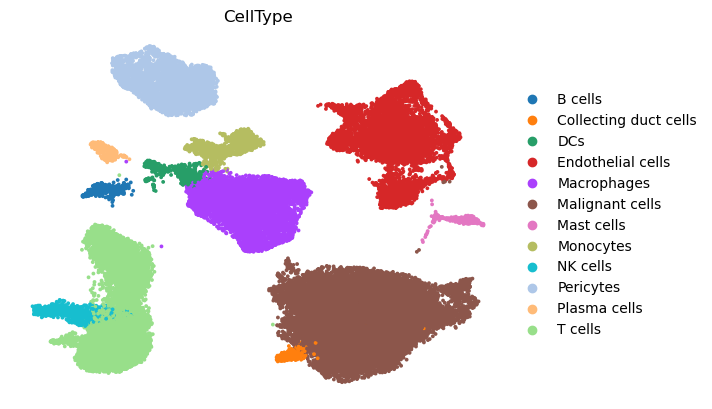

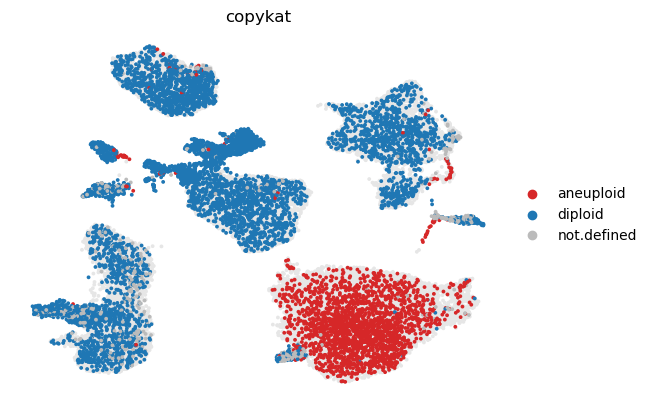

copykat,aneuploid,diploid,not.defined
CellType,,,
B cells,0.027,0.812,0.161
Collecting duct cells,0.135,0.423,0.441
DCs,0.016,0.974,0.010
Endothelial cells,0.024,0.942,0.034
Macrophages,0.004,0.982,0.014
Malignant cells,0.986,0.005,0.010
Mast cells,0.069,0.583,0.348
Monocytes,0.005,0.957,0.037
NK cells,0.001,0.860,0.138


In [ ]:
pred = pd.read_csv("part_1/RCC/copykat/RCC_prediction.tsv", sep="\t")
adata.obs["copykat"] = pd.Categorical(
    pred.set_index("cell.names")["copykat.pred"].reindex(adata.obs_names),
    categories=["aneuploid", "diploid", "not.defined"],
)
sc.pl.umap(adata, color="CellType", size=30, alpha=1, frameon=False)

sc.pl.umap(
    adata,
    color="copykat",
    palette={"aneuploid": "#d62728", "diploid": "#1f77b4", "not.defined": "#bbbbbb"},
    na_color="#e6e6e6",
    na_in_legend=False,
    size=30,
    alpha=1,
    frameon=False,
)

pd.crosstab(adata.obs["CellType"], adata.obs["copykat"], normalize="index").round(3)

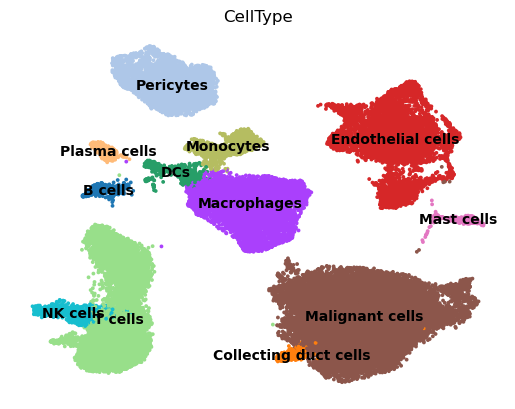

In [ ]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [48]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")